# Calidad del aire: análisis de tendencias y visualizaciones
**Proyecto 2 – Information Systems (cuarto periodo)** · Parte: análisis de gráficos

Este notebook parte de `calidad_aire_limpio.csv`, que sale de `calidad_aire_bogota.ipynb` (inventario, limpieza, regla de cobertura del 75 % y hashes de integridad). Aquí se hacen los pasos 3 y 4 del enunciado: **análisis de tendencias** y **visualizaciones**, comparando los datos con la norma colombiana y con las guías de la OMS.

Flujo: 1) cargar y validar → 2) depuración complementaria → 3) gráficos (G1–G8) → 4) tabla resumen y hallazgos.

Los gráficos se guardan en la carpeta `graficos/` para usarlos en la presentación.

## 1. Cargar datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

RUTA = 'calidad_aire_limpio.csv'     # mismo directorio que este notebook
if not os.path.exists(RUTA):          # en Colab: subir el archivo
    from google.colab import files
    files.upload()

GRAF = 'graficos'
os.makedirs(GRAF, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})

def guardar(fig, nombre):
    fig.savefig(os.path.join(GRAF, nombre))

datos = pd.read_csv(RUTA, parse_dates=['fecha'])
print(datos.shape)
print(datos['contaminante'].value_counts().to_string())
print('Rango de fechas:', datos['fecha'].min().date(), '→', datos['fecha'].max().date())

(83430, 5)
contaminante
PM10    53751
PM25    29679
Rango de fechas: 2004-01-01 → 2020-12-31


## 2. Depuración complementaria

Antes de graficar se revisaron los extremos. Hay dos cosas que corregir para que los gráficos no mientan:

1. **Valores centinela e imposibles.** La estación *La Ermita* (PM10, ago–oct 2019) tiene promedios diarios de varios miles de µg/m³ y valores exactos de `9999`, que es un código de "sin dato" del equipo, no una medición. El máximo diario plausible del resto de la red es ≈ 250 µg/m³. Se eliminan los valores **≥ 300 µg/m³**: incluye el código 9999 y los 19 días imposibles de La Ermita, y queda muy por encima del máximo real de cualquier otra estación.
2. **Dos ciudades en el mismo archivo.** Las estaciones *Base Aérea, Cañaveralejo, Compartir, ERA-Obrero, La Ermita, La Flora, Pance, Transitoria* y *Univalle* son de la red de **Cali** (DAGMA), no de la RMCAB de Bogotá. Se agrega la columna `ciudad` para no mezclarlas: los promedios "de Bogotá" solo usan estaciones de Bogotá.

In [2]:
CALI = {'Base Aérea', 'Cañaveralejo', 'Compartir', 'ERA-Obrero', 'La Ermita',
        'La Flora', 'Pance', 'Transitoria', 'Univalle'}
datos['ciudad'] = np.where(datos['estacion'].isin(CALI), 'Cali', 'Bogotá')

LIMITE_PLAUSIBLE = 300
malos = datos['valor'] >= LIMITE_PLAUSIBLE
print('Valores marcados como inválidos:', int(malos.sum()))
print(datos.loc[malos].groupby(['estacion', 'contaminante']).size().to_string())
datos = datos.loc[~malos].copy()

datos['contaminante'] = datos['contaminante'].replace({'PM25': 'PM2.5'})
datos['mes'] = datos['fecha'].dt.month
datos['dia_semana'] = datos['fecha'].dt.dayofweek
print()
print(datos.groupby(['ciudad', 'contaminante'])['estacion'].nunique().rename('estaciones').to_string())

Valores marcados como inválidos: 19
estacion   contaminante
La Ermita  PM10            19

ciudad  contaminante
Bogotá  PM10            13
        PM2.5           13
Cali    PM10             8
        PM2.5            4


### Valores de referencia

| Contaminante | Norma Colombia (Res. 2254 de 2017) 24 h | Norma Colombia anual | OMS 2021 24 h | OMS 2021 anual |
|---|---|---|---|---|
| PM10  | 75 µg/m³ | 50 µg/m³ | 45 µg/m³ | 15 µg/m³ |
| PM2.5 | 37 µg/m³ | 25 µg/m³ | 15 µg/m³ | 5 µg/m³ |

Los datos son **promedios diarios**, así que se comparan directamente con los límites de 24 h; los promedios anuales se comparan con los límites anuales.

In [3]:
NORMA = {'PM10': {'24h': 75, 'anual': 50}, 'PM2.5': {'24h': 37, 'anual': 25}}
OMS   = {'PM10': {'24h': 45, 'anual': 15}, 'PM2.5': {'24h': 15, 'anual': 5}}
COLOR_CIUDAD = {'Bogotá': '#2a6fdb', 'Cali': '#e07b39'}

## 3. Gráficos

### G1. Tendencia del promedio anual por ciudad

Para cada estación se calcula su promedio anual y luego se promedian las estaciones de la ciudad (así una estación con más días no pesa más). La banda sombreada es el rango entre la estación más limpia y la más contaminada de ese año.

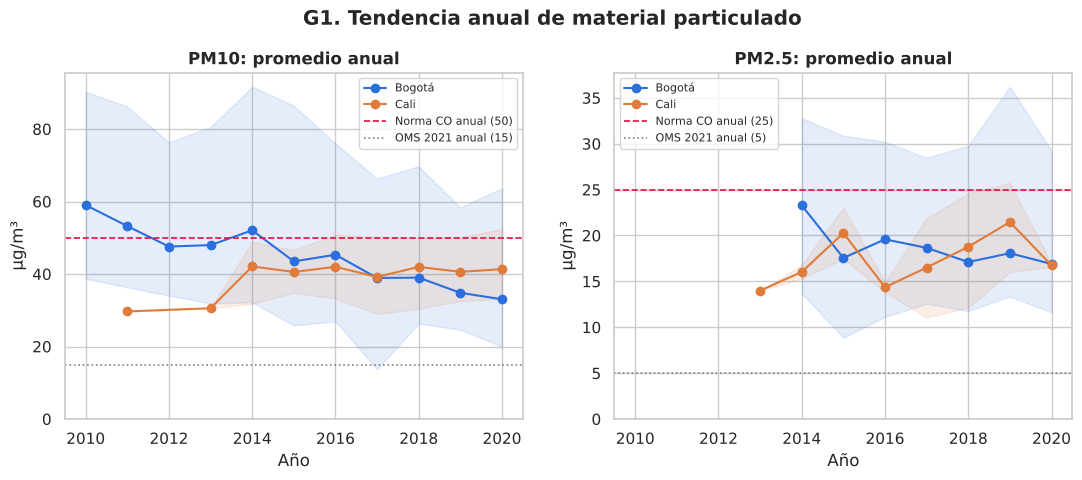

,ciudad,contaminante,años,pendiente_µg/m³_por_año,primer_año,último_año
0,Bogotá,PM10,2010–2020,-2.31,59.0,33.0
1,Bogotá,PM2.5,2014–2020,-0.74,23.3,16.9
2,Cali,PM10,2011–2020,1.22,29.7,41.3
3,Cali,PM2.5,2013–2020,0.53,14.0,16.7


In [4]:
anual_est = (datos.groupby(['ciudad', 'contaminante', 'estacion', 'anio'])['valor']
             .mean().reset_index())
anual = (anual_est.groupby(['ciudad', 'contaminante', 'anio'])['valor']
         .agg(['mean', 'min', 'max', 'count']).reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    for ciudad, g in anual[anual['contaminante'] == cont].groupby('ciudad'):
        g = g[g['anio'] >= 2010]
        ax.plot(g['anio'], g['mean'], marker='o', color=COLOR_CIUDAD[ciudad], label=ciudad)
        ax.fill_between(g['anio'], g['min'], g['max'], color=COLOR_CIUDAD[ciudad], alpha=0.12)
    ax.axhline(NORMA[cont]['anual'], color='crimson', ls='--', lw=1.2,
               label=f"Norma CO anual ({NORMA[cont]['anual']})")
    ax.axhline(OMS[cont]['anual'], color='gray', ls=':', lw=1.2,
               label=f"OMS 2021 anual ({OMS[cont]['anual']})")
    ax.set_title(f'{cont}: promedio anual')
    ax.set_xlabel('Año'); ax.set_ylabel('µg/m³')
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
fig.suptitle('G1. Tendencia anual de material particulado', y=1.02, fontweight='bold')
guardar(fig, 'G1_tendencia_anual.png')
plt.show()

pend = []
for (ciudad, cont), g in anual[anual['anio'] >= 2010].groupby(['ciudad', 'contaminante']):
    if len(g) >= 4:
        m = np.polyfit(g['anio'], g['mean'], 1)[0]
        pend.append({'ciudad': ciudad, 'contaminante': cont, 'años': f"{g['anio'].min()}–{g['anio'].max()}",
                     'pendiente_µg/m³_por_año': round(m, 2),
                     'primer_año': round(g['mean'].iloc[0], 1), 'último_año': round(g['mean'].iloc[-1], 1)})
pd.DataFrame(pend)

**Lectura de G1.**
- **Bogotá mejora de forma sostenida en PM10**: el promedio de la red bajó de ≈ 59 µg/m³ (2010) a ≈ 33 µg/m³ (2020), unos −2,3 µg/m³ por año. Desde 2015 el promedio de la ciudad cumple la norma anual colombiana (50 µg/m³), aunque la banda muestra que la estación más contaminada (Carvajal) sigue por encima.
- **PM2.5 en Bogotá baja más despacio** (≈ −0,7 µg/m³ por año, de 23 a 17 µg/m³). El promedio cumple la norma colombiana (25), pero triplica la guía OMS (5).
- **Cali no muestra mejora**: PM10 se mantiene alrededor de 40 µg/m³ desde 2014 y PM2.5 sube hasta 2019. Ojo: Cali tiene pocas estaciones de PM2.5 (1–3 por año), así que esa curva es menos robusta.
- **Ninguna estación de ninguna ciudad cumple la guía OMS 2021** en ningún año.

### G2. Promedio anual por estación (mapa de calor)

Muestra qué estaciones son las más contaminadas y si la mejora es general o de unas pocas. Celdas vacías = año sin cobertura suficiente (no pasó la regla del 75 %). En rojo, los años que superan la norma anual colombiana.

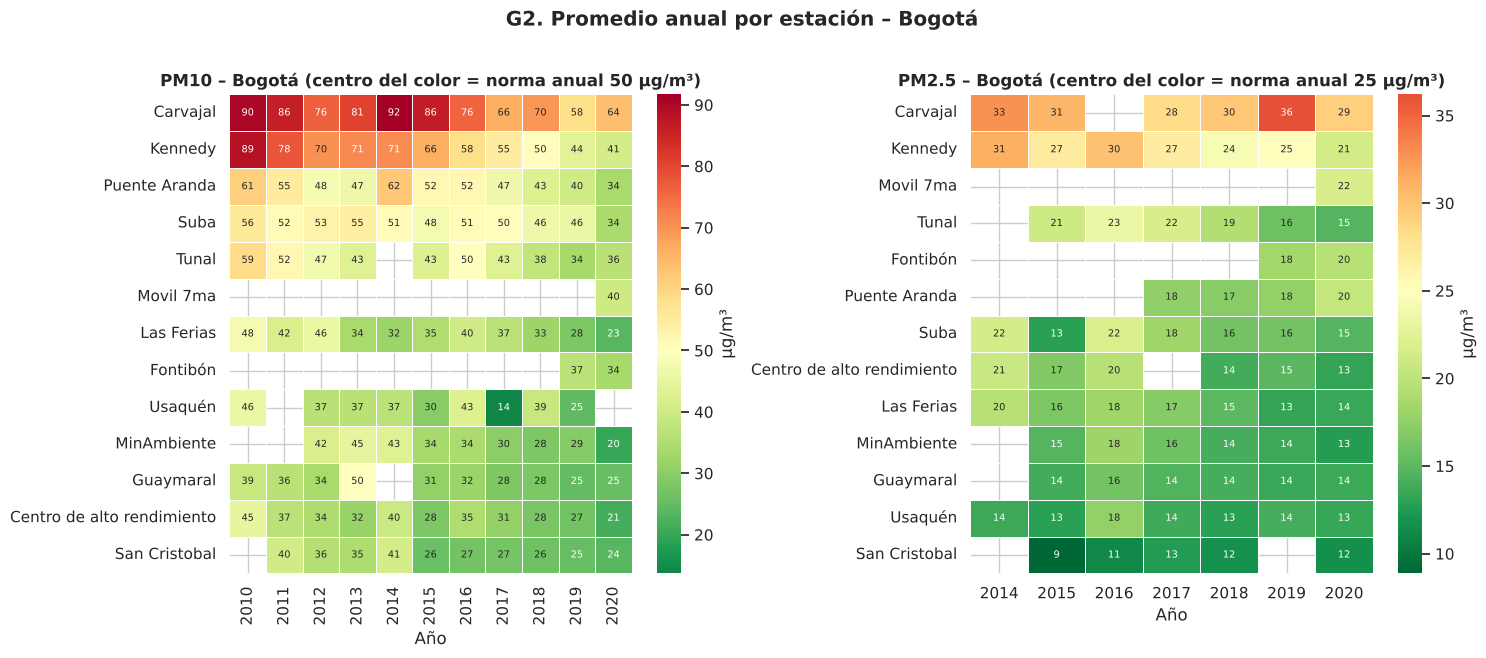

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    t = (anual_est[(anual_est['contaminante'] == cont) & (anual_est['ciudad'] == 'Bogotá') &
                   (anual_est['anio'] >= 2010)]
         .pivot(index='estacion', columns='anio', values='valor'))
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    lim = NORMA[cont]['anual']
    sns.heatmap(t, ax=ax, cmap='RdYlGn_r', center=lim, annot=True, fmt='.0f',
                annot_kws={'size': 7}, linewidths=0.4, linecolor='white',
                cbar_kws={'label': 'µg/m³'})
    ax.set_title(f'{cont} – Bogotá (centro del color = norma anual {lim} µg/m³)')
    ax.set_xlabel('Año'); ax.set_ylabel('')
fig.suptitle('G2. Promedio anual por estación – Bogotá', y=1.01, fontweight='bold')
fig.tight_layout()
guardar(fig, 'G2_heatmap_estaciones_bogota.png')
plt.show()

**Lectura de G2.**
- El problema está **concentrado en el suroccidente de Bogotá**: Carvajal y Kennedy encabezan ambas tablas todos los años, y son las únicas que superan la norma anual de PM2.5 (Carvajal en todos los años, Kennedy hasta 2017). Es la zona de la Autopista Sur, alto tráfico de carga y actividad industrial.
- La mejora en PM10 es **general**: casi todas las estaciones pasan de tonos amarillos/naranja en 2010–2014 a verdes en 2019–2020. Kennedy baja de 89 a 41 µg/m³.
- El norte y oriente (Usaquén, Guaymaral, San Cristóbal, MinAmbiente) son sistemáticamente los más limpios.
- Celdas vacías y años aislados (p. ej. Usaquén PM10 2017 = 14) son años con poca cobertura; se leen con cuidado.

### G3. Distribución diaria por estación

Diagrama de caja de los promedios diarios (2015–2020, periodo en que casi todas las estaciones tienen datos). Las estaciones están ordenadas por mediana. Las líneas marcan los límites de 24 h.

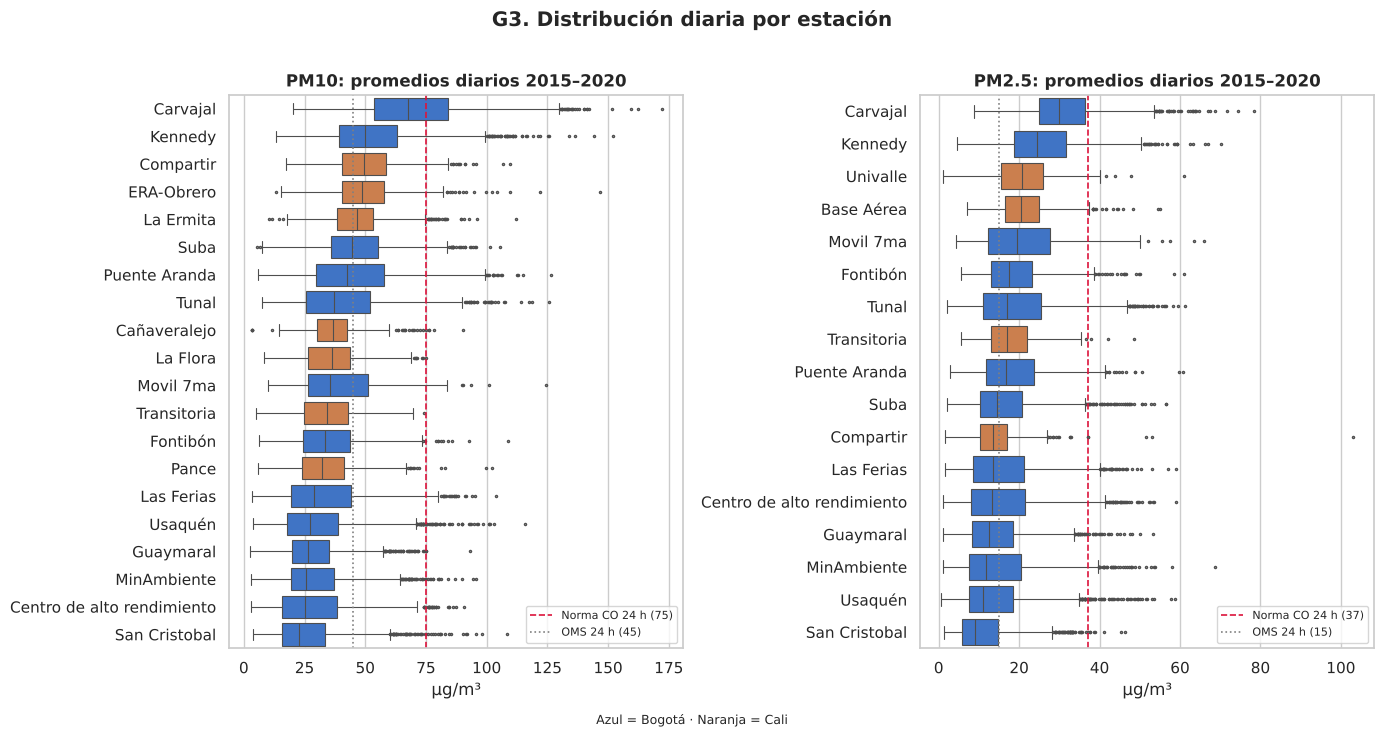

In [6]:
rec = datos[datos['anio'] >= 2015]
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    d = rec[rec['contaminante'] == cont]
    orden = d.groupby('estacion')['valor'].median().sort_values(ascending=False).index
    pal = {e: COLOR_CIUDAD['Cali' if e in CALI else 'Bogotá'] for e in orden}
    sns.boxplot(data=d, y='estacion', x='valor', order=orden, hue='estacion', palette=pal,
                legend=False, ax=ax, fliersize=1.5, linewidth=0.8)
    ax.axvline(NORMA[cont]['24h'], color='crimson', ls='--', lw=1.2, label=f"Norma CO 24 h ({NORMA[cont]['24h']})")
    ax.axvline(OMS[cont]['24h'], color='gray', ls=':', lw=1.2, label=f"OMS 24 h ({OMS[cont]['24h']})")
    ax.set_title(f'{cont}: promedios diarios 2015–2020')
    ax.set_xlabel('µg/m³'); ax.set_ylabel('')
    ax.legend(fontsize=8, loc='lower right')
fig.text(0.5, -0.01, 'Azul = Bogotá · Naranja = Cali', ha='center', fontsize=9)
fig.suptitle('G3. Distribución diaria por estación', y=1.01, fontweight='bold')
fig.tight_layout()
guardar(fig, 'G3_boxplot_estaciones.png')
plt.show()

**Lectura de G3.**
- En PM10, **la mediana de Carvajal (≈ 67 µg/m³) está cerca del límite diario** y su caja cruza la norma: uno de cada tres días la supera. Kennedy es la segunda.
- En PM2.5 la mitad de las estaciones tiene la mediana **por encima de la guía OMS de 24 h (15 µg/m³)**: un día "típico" ya supera lo que la OMS recomienda.
- Las estaciones de Cali (naranja) tienen cajas más angostas: menos variabilidad y menos picos que Bogotá, pero niveles medios parecidos o más altos en PM10 (Compartir, ERA-Obrero, La Ermita).
- Los puntos aislados a la derecha son episodios críticos; en Bogotá se agrupan en los primeros meses del año (ver G4 y G7).

### G4. Estacionalidad: perfil mensual

Promedio por mes del año, calculado sobre todos los años disponibles. Se normaliza contra el promedio de cada estación (100 % = promedio de la estación) para que las estaciones más sucias no dominen el patrón.

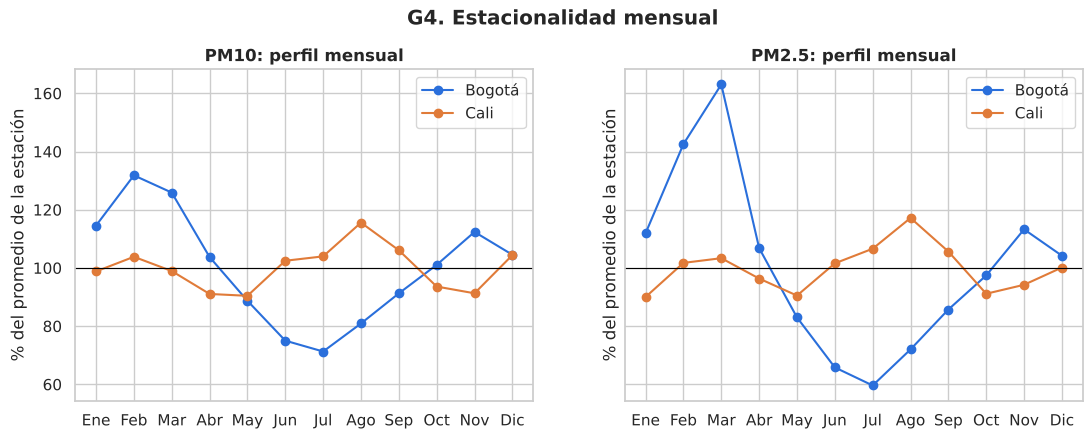

ciudad       Bogotá          Cali       
contaminante   PM10  PM2.5   PM10  PM2.5
Ene           115.0  112.0   99.0   90.0
Feb           132.0  143.0  104.0  102.0
Mar           126.0  163.0   99.0  103.0
Abr           104.0  107.0   91.0   96.0
May            89.0   83.0   90.0   90.0
Jun            75.0   66.0  102.0  102.0
Jul            71.0   60.0  104.0  107.0
Ago            81.0   72.0  116.0  117.0
Sep            91.0   86.0  106.0  106.0
Oct           101.0   97.0   94.0   91.0
Nov           112.0  113.0   91.0   94.0
Dic           105.0  104.0  104.0  100.0

In [7]:
d = datos.copy()
d['rel'] = d['valor'] / d.groupby(['estacion', 'contaminante'])['valor'].transform('mean') * 100
perfil = d.groupby(['ciudad', 'contaminante', 'mes'])['rel'].mean().reset_index()

meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    for ciudad, g in perfil[perfil['contaminante'] == cont].groupby('ciudad'):
        ax.plot(g['mes'], g['rel'], marker='o', color=COLOR_CIUDAD[ciudad], label=ciudad)
    ax.axhline(100, color='black', lw=0.8)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses)
    ax.set_title(f'{cont}: perfil mensual'); ax.set_ylabel('% del promedio de la estación')
    ax.legend()
fig.suptitle('G4. Estacionalidad mensual', y=1.02, fontweight='bold')
guardar(fig, 'G4_estacionalidad_mensual.png')
plt.show()

piv = perfil.pivot_table(index='mes', columns=['ciudad', 'contaminante'], values='rel').round(0)
piv.index = meses
piv

**Lectura de G4.**
- **Bogotá tiene una estacionalidad muy marcada**: febrero–marzo es la peor época (PM2.5 hasta 63 % por encima del promedio en marzo) y junio–agosto la mejor (hasta 40 % por debajo en julio). Es un patrón bimodal con un segundo pico más suave en noviembre.
- El pico de inicio de año coincide con la temporada seca, la menor altura de mezcla de la atmósfera y la temporada de incendios forestales en la Orinoquía, cuyo humo llega a la ciudad; los vientos de mitad de año (temporada de vientos alisios) dispersan los contaminantes.
- PM2.5 varía más que PM10, lo que apunta a fuentes de combustión (incendios, diésel) más que a polvo resuspendido.
- **Cali casi no tiene estacionalidad** (90–117 %), con un máximo leve en agosto.
- **Implicación**: las medidas de contingencia (restricciones extra, alertas) deberían planearse con anticipación para febrero–marzo.

### G5. Patrón semanal

Mismo cálculo relativo, por día de la semana. Si el tráfico y la industria son fuentes importantes, el domingo debería ser claramente más limpio.

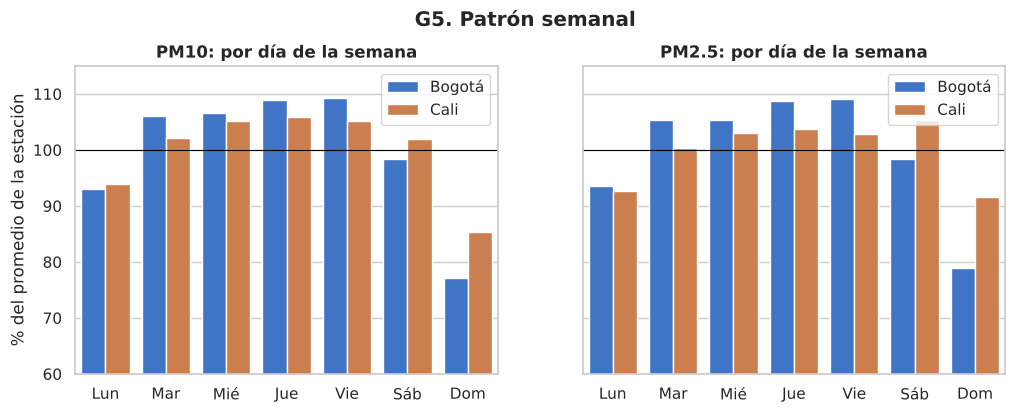

ciudad       Bogotá          Cali       
contaminante   PM10  PM2.5   PM10  PM2.5
Lun            93.0   94.0   94.0   93.0
Mar           106.0  105.0  102.0  100.0
Mié           107.0  105.0  105.0  103.0
Jue           109.0  109.0  106.0  104.0
Vie           109.0  109.0  105.0  103.0
Sáb            98.0   98.0  102.0  105.0
Dom            77.0   79.0   85.0   92.0

In [8]:
sem = d.groupby(['ciudad', 'contaminante', 'dia_semana'])['rel'].mean().reset_index()
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    s = sem[sem['contaminante'] == cont]
    sns.barplot(data=s, x='dia_semana', y='rel', hue='ciudad', palette=COLOR_CIUDAD, ax=ax)
    ax.axhline(100, color='black', lw=0.8)
    ax.set_xticks(range(7)); ax.set_xticklabels(dias)
    ax.set_title(f'{cont}: por día de la semana'); ax.set_xlabel(''); ax.set_ylabel('% del promedio de la estación')
    ax.set_ylim(60, 115)
    ax.legend(title='')
fig.suptitle('G5. Patrón semanal', y=1.02, fontweight='bold')
guardar(fig, 'G5_patron_semanal.png')
plt.show()

sem.pivot_table(index='dia_semana', columns=['ciudad', 'contaminante'], values='rel').round(0).set_axis(dias)

**Lectura de G5.**
- En Bogotá el **domingo es ≈ 22 % más limpio** que el promedio y el sábado ≈ 2 % menos; de martes a viernes se está entre 5 % y 9 % por encima. El lunes sale bajo probablemente porque incluye festivos ("puentes") y el arrastre del domingo.
- Este "efecto fin de semana" es la huella del **tráfico y la actividad económica**: lo que cambia entre un jueves y un domingo es la actividad humana, no el clima.
- En Cali el efecto existe pero es menor (domingo −8 % a −15 %).

### G6. Días que superan los límites de 24 h

Porcentaje de días medidos (2015–2020) en que el promedio diario superó la norma colombiana y la guía de la OMS. Es el indicador más directo de exposición de la población.

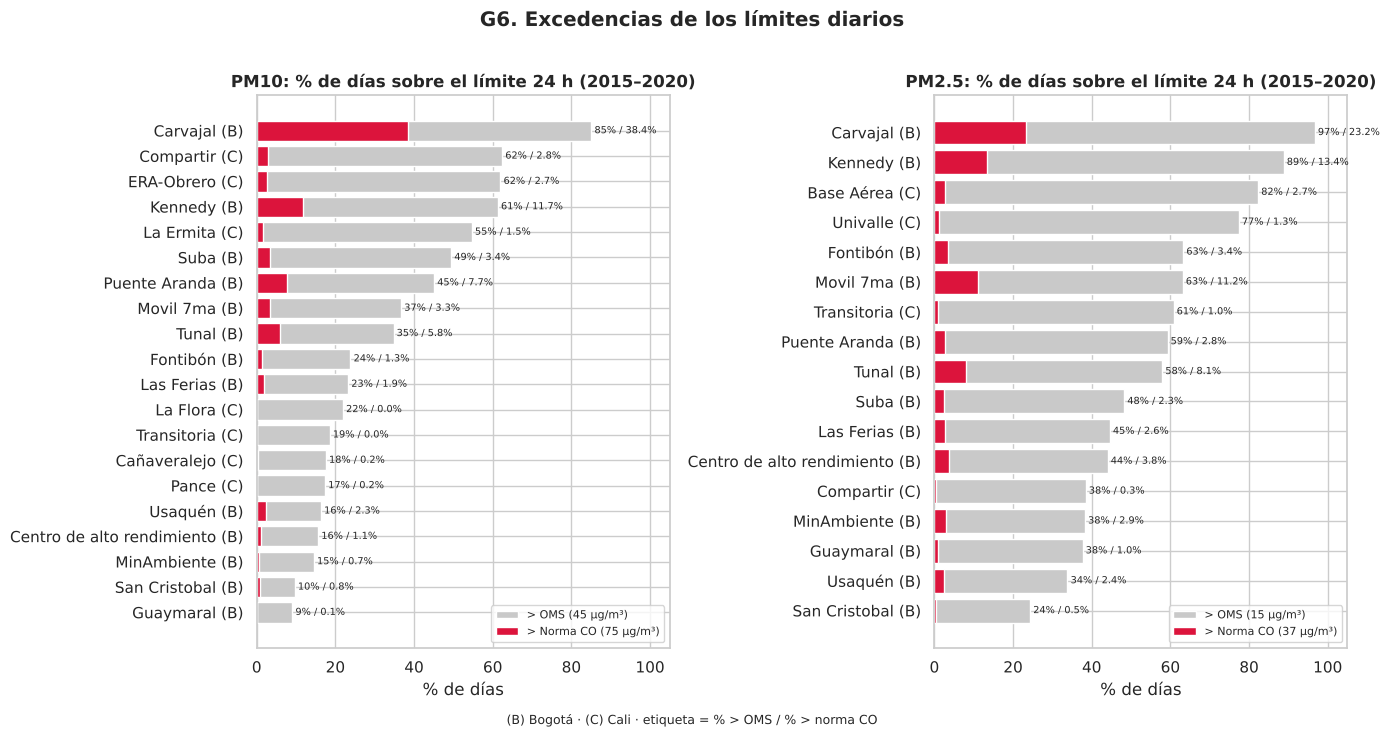

,ciudad,estacion,contaminante,dias,% > norma CO,% > OMS
0,Bogotá,Carvajal,PM10,2097,38.4,85.1
8,Bogotá,Kennedy,PM10,2150,11.7,61.3
16,Bogotá,Puente Aranda,PM10,2162,7.7,45.1
22,Bogotá,Tunal,PM10,2145,5.8,34.8
20,Bogotá,Suba,PM10,2061,3.4,49.4
14,Bogotá,Movil 7ma,PM10,365,3.3,36.7
28,Cali,Compartir,PM10,1646,2.8,62.4
30,Cali,ERA-Obrero,PM10,1401,2.7,62.0
24,Bogotá,Usaquén,PM10,1738,2.3,16.3
10,Bogotá,Las Ferias,PM10,2121,1.9,23.2


In [9]:
filas = []
for (ciudad, est, cont), g in rec.groupby(['ciudad', 'estacion', 'contaminante']):
    if len(g) < 300:            # menos de ~1 año de datos: no comparable
        continue
    filas.append({'ciudad': ciudad, 'estacion': est, 'contaminante': cont, 'dias': len(g),
                  '% > norma CO': (g['valor'] > NORMA[cont]['24h']).mean() * 100,
                  '% > OMS': (g['valor'] > OMS[cont]['24h']).mean() * 100})
exced = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    e = exced[exced['contaminante'] == cont].sort_values('% > OMS')
    y = np.arange(len(e))
    ax.barh(y, e['% > OMS'], color='#c9c9c9', label=f"> OMS ({OMS[cont]['24h']} µg/m³)")
    ax.barh(y, e['% > norma CO'], color='crimson', label=f"> Norma CO ({NORMA[cont]['24h']} µg/m³)")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{r.estacion} ({'C' if r.ciudad == 'Cali' else 'B'})" for r in e.itertuples()])
    for yi, (a, b) in enumerate(zip(e['% > norma CO'], e['% > OMS'])):
        ax.text(b + 0.8, yi, f'{b:.0f}% / {a:.1f}%', va='center', fontsize=7)
    ax.set_xlim(0, 105)
    ax.set_title(f'{cont}: % de días sobre el límite 24 h (2015–2020)')
    ax.set_xlabel('% de días'); ax.legend(fontsize=8, loc='lower right')
fig.text(0.5, -0.01, '(B) Bogotá · (C) Cali · etiqueta = % > OMS / % > norma CO', ha='center', fontsize=9)
fig.suptitle('G6. Excedencias de los límites diarios', y=1.01, fontweight='bold')
fig.tight_layout()
guardar(fig, 'G6_excedencias.png')
plt.show()

exced.sort_values(['contaminante', '% > norma CO'], ascending=[True, False]).round(1)

**Lectura de G6.**
- **Carvajal supera la norma colombiana de PM10 en 38 % de los días** y la de PM2.5 en 23 %. Kennedy, Móvil 7ma y Tunal también tienen excedencias frecuentes de PM2.5 (8–13 % de los días).
- Con la guía OMS el panorama cambia: en PM2.5, **Carvajal la supera el 97 % de los días y Kennedy el 89 %**; incluso la estación más limpia (San Cristóbal) la supera uno de cada cuatro días.
- Las estaciones de Cali casi nunca superan la norma colombiana (< 3 %) pero sí la OMS con mucha frecuencia (hasta 82 % en PM2.5 en Base Aérea): niveles moderados pero constantes.
- La distancia entre las barras rojas y grises muestra que **la norma colombiana es mucho más permisiva que la OMS**; cumplirla no significa que el aire sea saludable.

### G7. Serie diaria de Bogotá con media móvil

Promedio diario de todas las estaciones de Bogotá y media móvil de 30 días. Permite ver episodios críticos (picos de varias semanas) que el promedio anual esconde.

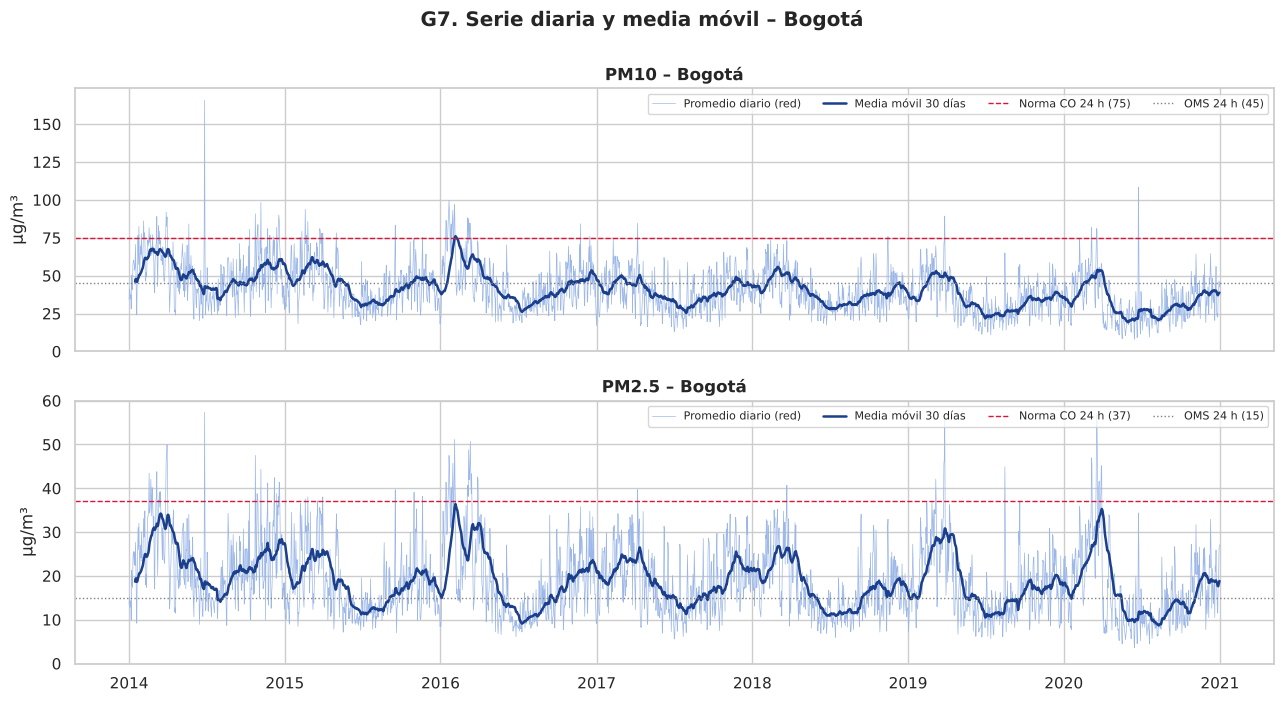

,contaminante,fecha,valor
177,PM10,2014-06-27,165.7
2366,PM10,2020-06-24,108.4
750,PM10,2016-01-21,99.7
309,PM10,2014-11-06,98.3
763,PM10,2016-02-03,96.9
2734,PM2.5,2014-06-27,57.3
4826,PM2.5,2020-03-19,56.8
4469,PM2.5,2019-03-28,56.7
4825,PM2.5,2020-03-18,54.6
3320,PM2.5,2016-02-03,51.2


In [10]:
bog = datos[(datos['ciudad'] == 'Bogotá') & (datos['anio'] >= 2014)]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    s = bog[bog['contaminante'] == cont].groupby('fecha')['valor'].mean().asfreq('D')
    ax.plot(s.index, s, color='#9db8e8', lw=0.5, label='Promedio diario (red)')
    ax.plot(s.index, s.rolling(30, min_periods=15).mean(), color='#1b3f8b', lw=1.8, label='Media móvil 30 días')
    ax.axhline(NORMA[cont]['24h'], color='crimson', ls='--', lw=1, label=f"Norma CO 24 h ({NORMA[cont]['24h']})")
    ax.axhline(OMS[cont]['24h'], color='gray', ls=':', lw=1, label=f"OMS 24 h ({OMS[cont]['24h']})")
    ax.set_title(f'{cont} – Bogotá'); ax.set_ylabel('µg/m³'); ax.set_ylim(bottom=0)
    ax.legend(fontsize=8, ncol=4, loc='upper right')
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('G7. Serie diaria y media móvil – Bogotá', y=1.0, fontweight='bold')
fig.tight_layout()
guardar(fig, 'G7_serie_bogota.png')
plt.show()

top = (bog.groupby(['contaminante', 'fecha'])['valor'].mean().reset_index()
       .sort_values('valor', ascending=False).groupby('contaminante').head(5))
top.round(1)

**Lectura de G7.**
- La media móvil muestra el ciclo anual de G4 repitiéndose cada año, con picos en febrero–marzo de 2014, 2016, 2019 y 2020.
- **Peores episodios**: febrero de 2016 (la media de 30 días de PM2.5 llega a ≈ 36 µg/m³, casi el límite diario como promedio de un mes entero; coincide con el fenómeno de El Niño 2015–2016) y marzo de 2020 (PM2.5 diario de la red ≈ 57 µg/m³ el 18–19 de marzo).
- Justo después de marzo de 2020 se ve la caída más fuerte de toda la serie: la cuarentena (ver G8).
- El pico aislado del 27 de junio de 2014 (PM10 ≈ 166 µg/m³ como promedio de toda la red) es un día puntual; puede ser un evento real (quemas, pólvora) o un error de medición, y vale la pena verificarlo con la fuente.

### G8. Efecto de la cuarentena de 2020

Compara cada mes de 2020 con el promedio del mismo mes en 2017–2019, por estación, y muestra la mediana de las estaciones. La cuarentena nacional empezó el 25 de marzo de 2020 (simulacro en Bogotá desde el 20 de marzo); es un "experimento natural" que muestra cuánto pesa el tráfico.

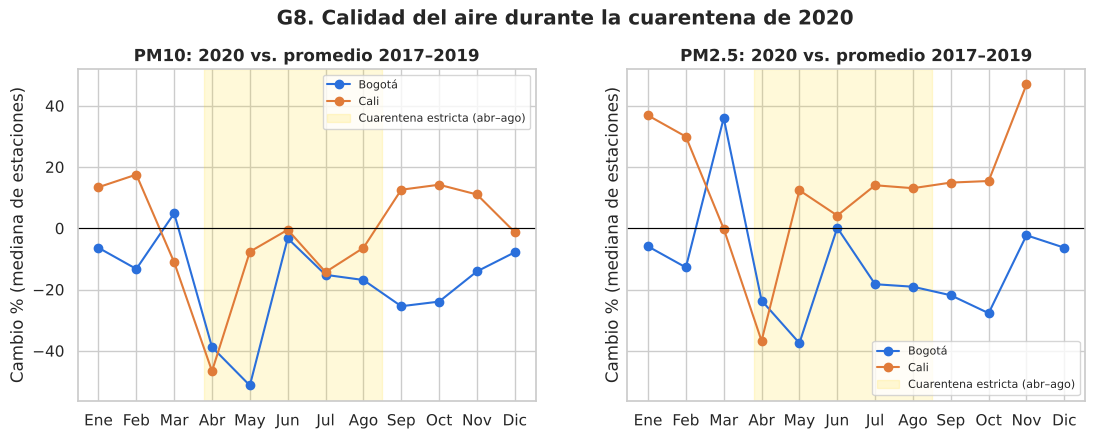

ciudad       Bogotá        Cali      
contaminante   PM10 PM2.5  PM10 PM2.5
Ene            -6.0  -6.0  13.0  37.0
Feb           -13.0 -13.0  18.0  30.0
Mar             5.0  36.0 -11.0  -0.0
Abr           -39.0 -24.0 -47.0 -37.0
May           -51.0 -37.0  -8.0  12.0
Jun            -3.0   0.0  -0.0   4.0
Jul           -15.0 -18.0 -14.0  14.0
Ago           -17.0 -19.0  -6.0  13.0
Sep           -25.0 -22.0  13.0  15.0
Oct           -24.0 -28.0  14.0  15.0
Nov           -14.0  -2.0  11.0  47.0
Dic            -8.0  -6.0  -1.0   NaN

In [11]:
base = (datos[datos['anio'].between(2017, 2019)]
        .groupby(['ciudad', 'contaminante', 'estacion', 'mes'])['valor'].mean().rename('base'))
y20 = (datos[datos['anio'] == 2020]
       .groupby(['ciudad', 'contaminante', 'estacion', 'mes'])['valor'].mean().rename('v2020'))
comp = pd.concat([base, y20], axis=1).dropna().reset_index()
comp['cambio_%'] = (comp['v2020'] / comp['base'] - 1) * 100
med = comp.groupby(['ciudad', 'contaminante', 'mes'])['cambio_%'].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, cont in zip(axes, ['PM10', 'PM2.5']):
    for ciudad, g in med[med['contaminante'] == cont].groupby('ciudad'):
        ax.plot(g['mes'], g['cambio_%'], marker='o', color=COLOR_CIUDAD[ciudad], label=ciudad)
    ax.axhline(0, color='black', lw=0.8)
    ax.axvspan(3.8, 8.5, color='gold', alpha=0.15, label='Cuarentena estricta (abr–ago)')
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses)
    ax.set_title(f'{cont}: 2020 vs. promedio 2017–2019'); ax.set_ylabel('Cambio % (mediana de estaciones)')
    ax.legend(fontsize=8)
fig.suptitle('G8. Calidad del aire durante la cuarentena de 2020', y=1.02, fontweight='bold')
guardar(fig, 'G8_cuarentena_2020.png')
plt.show()

med.pivot_table(index='mes', columns=['ciudad', 'contaminante'], values='cambio_%').round(0).set_axis(meses)

**Lectura de G8.**
- En **Bogotá**, abril y mayo de 2020 tuvieron entre 24 % y 51 % menos material particulado que el promedio 2017–2019. De julio a octubre, con reapertura gradual, siguió entre 15 % y 28 % por debajo.
- Marzo de 2020 sale **por encima** de lo normal en PM2.5 (+36 %): el episodio crítico de mediados de marzo (G7) ocurrió antes de la cuarentena.
- En **Cali** la caída se ve en abril (−37 % a −47 %), pero desde mayo los valores vuelven a la normalidad o la superan. La curva de PM2.5 de Cali descansa en solo 1–2 estaciones con datos en 2020, así que es poco robusta.
- **Conclusión**: el experimento natural de la cuarentena confirma que **el tráfico y la actividad urbana explican una parte grande** del material particulado en Bogotá, consistente con G5.

## 4. Tabla resumen por estación

In [12]:
resumen = (datos[datos['anio'] >= 2015]
           .groupby(['ciudad', 'estacion', 'contaminante'])['valor']
           .agg(dias='count', promedio='mean', p95=lambda x: x.quantile(0.95), maximo='max')
           .reset_index())
resumen = resumen.merge(exced[['estacion', 'contaminante', '% > norma CO', '% > OMS']],
                        on=['estacion', 'contaminante'], how='left')
resumen['supera_norma_anual'] = resumen.apply(
    lambda r: r['promedio'] > NORMA[r['contaminante']]['anual'], axis=1)
resumen = resumen.round(1).sort_values(['contaminante', 'promedio'], ascending=[True, False])
resumen.to_csv(os.path.join(GRAF, 'resumen_estaciones.csv'), index=False)
resumen

,ciudad,estacion,contaminante,dias,promedio,p95,maximo,% > norma CO,% > OMS,supera_norma_anual
0,Bogotá,Carvajal,PM10,2097,70.1,113.1,172.4,38.4,85.1,True
8,Bogotá,Kennedy,PM10,2150,52.3,87.2,151.9,11.7,61.3,True
28,Cali,Compartir,PM10,1646,49.8,72.1,109.5,2.8,62.4,False
30,Cali,ERA-Obrero,PM10,1401,49.3,71.0,146.6,2.7,62.0,False
31,Cali,La Ermita,PM10,1971,46.3,64.7,112.2,1.5,54.7,False
20,Bogotá,Suba,PM10,2061,45.6,71.8,105.5,3.4,49.4,False
16,Bogotá,Puente Aranda,PM10,2162,44.6,80.8,126.5,7.7,45.1,False
22,Bogotá,Tunal,PM10,2145,40.5,77.4,125.5,5.8,34.8,False
14,Bogotá,Movil 7ma,PM10,365,39.8,70.6,124.5,3.3,36.7,False
27,Cali,Cañaveralejo,PM10,1615,36.7,51.9,90.1,0.2,17.6,False


Nota: `supera_norma_anual` compara el **promedio 2015–2020** de la estación con la norma anual; los años individuales están en G2.

In [13]:
print('Archivos generados en', GRAF + '/:')
for f in sorted(os.listdir(GRAF)):
    print('  ', f)

Archivos generados en graficos/:
   G1_tendencia_anual.png
   G2_heatmap_estaciones_bogota.png
   G3_boxplot_estaciones.png
   G4_estacionalidad_mensual.png
   G5_patron_semanal.png
   G6_excedencias.png
   G7_serie_bogota.png
   G8_cuarentena_2020.png
   resumen_estaciones.csv


## 5. Conclusiones del análisis gráfico

1. **Tendencia**: Bogotá mejoró de forma clara en PM10 (≈ −44 % entre 2010 y 2020) y más modestamente en PM2.5. Cali no muestra mejora.
2. **Zonas críticas**: el suroccidente de Bogotá (Carvajal, Kennedy y en menor medida Tunal y Puente Aranda) concentra las excedencias. Carvajal es la única estación que incumple la norma colombiana anual en ambos contaminantes en casi todos los años.
3. **Temporalidad**: febrero–marzo es la época crítica en Bogotá; julio la mejor. Los días laborales son más contaminados que los domingos.
4. **Fuentes**: el efecto fin de semana y la caída durante la cuarentena de 2020 apuntan a que el tráfico y la actividad urbana son una fuente principal; el pico de inicio de año sugiere además un aporte regional (incendios, condiciones secas).
5. **Norma vs. salud**: casi todas las estaciones cumplen la norma colombiana anual, pero **ninguna cumple la guía OMS 2021**. La norma vigente es permisiva frente a la evidencia en salud.

**Propuestas basadas en los datos**
- Priorizar el suroccidente (Carvajal–Kennedy) en control de flota de carga y transporte público diésel.
- Activar medidas preventivas antes de febrero (alertas tempranas, restricciones temporales), no solo cuando ya hay episodio.
- Avanzar hacia las metas intermedias de la OMS, como plantea la Res. 2254 de 2017 para 2030.

**Limitaciones**
- El archivo mezcla estaciones de Bogotá y Cali; aquí se separaron, pero conviene confirmarlo con la fuente original.
- Cali tiene pocas estaciones de PM2.5 y series cortas.
- La regla del 75 % deja años sueltos en algunas estaciones (celdas vacías en G2), por lo que las tendencias por estación son aproximadas.